In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
!pip install xgboost catboost imbalanced-learn

In [ ]:
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import ExtraTreesClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# For imbalance handling
from imblearn.over_sampling import SMOTE

In [ ]:
df = pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
print(df.shape)
print(df['Class'].value_counts())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [ ]:
# preprocessig
X = df.drop('Class', axis=1)
y = df['Class']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42
)

In [ ]:
#  Apply SMOTE ONLY on training data
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

print(pd.Series(y_train).value_counts())

Class
1    227565
0    227565
Name: count, dtype: int64


In [ ]:
# XGBoost
xgb = XGBClassifier(eval_metric='logloss')
xgb.fit(X_train, y_train)
# CatBoost
cat = CatBoostClassifier(verbose=0)
cat.fit(X_train, y_train)

CatBoostClassifier(verbose=0)

In [ ]:
# Extra Trees
et = ExtraTreesClassifier()
et.fit(X_train, y_train)

ExtraTreesClassifier()

In [ ]:
# soft voting
# Get probabilities
et_pred = et.predict_proba(X_test)
xgb_pred = xgb.predict_proba(X_test)
cat_pred = cat.predict_proba(X_test)

# Average probabilities
avg_pred = (et_pred + xgb_pred + cat_pred) / 3

# Final prediction
y_pred = np.argmax(avg_pred, axis=1)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.999806552591316
Precision: 0.9996140215446156
Recall: 1.0
F1 Score: 0.9998069735202766


In [ ]:
train_pred = np.argmax(
    (et.predict_proba(X_train) +
     xgb.predict_proba(X_train) +
     cat.predict_proba(X_train)) / 3, axis=1)

print("Train Accuracy:", accuracy_score(y_train, train_pred))

Train Accuracy: 0.9999934084766989


In [ ]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

[[56728    22]
 [    0 56976]]


In [ ]:
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Test Accuracy: 0.999806552591316


In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(et, X_resampled, y_resampled, cv=5)
print(scores.mean())

0.9985983855934439


In [ ]:
from sklearn.metrics import roc_auc_score

print("ROC AUC:", roc_auc_score(y_test, y_pred))

ROC AUC: 0.9998061674008811


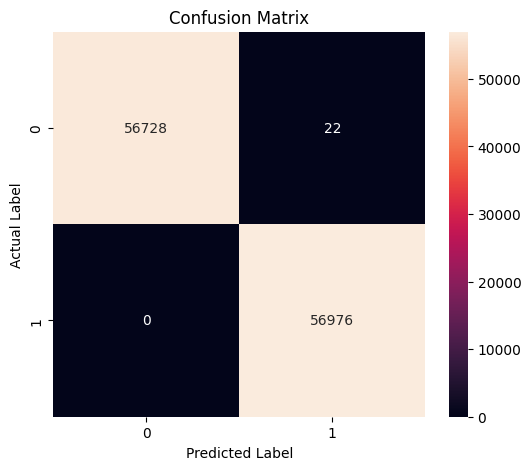

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d')

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

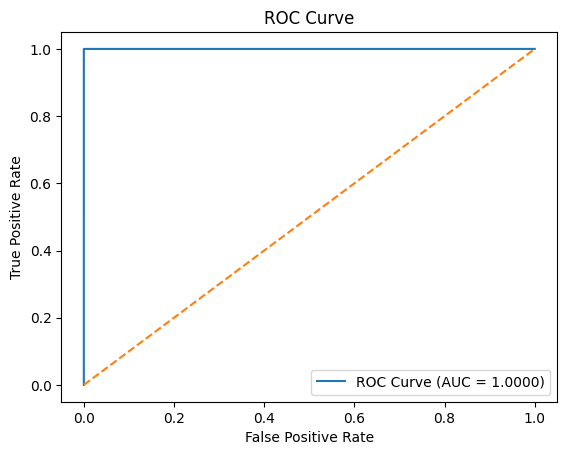

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get probabilities (IMPORTANT: use probabilities, not labels)
y_prob = (et.predict_proba(X_test)[:,1] +
          xgb.predict_proba(X_test)[:,1] +
          cat.predict_proba(X_test)[:,1]) / 3

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, label="ROC Curve (AUC = %0.4f)" % roc_auc_score(y_test, y_prob))

plt.plot([0,1], [0,1], linestyle='--')  # diagonal line

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

In [ ]:
def predict_transaction(sample):
    prob = (et.predict_proba(sample) +
            xgb.predict_proba(sample) +
            cat.predict_proba(sample)) / 3

    pred = np.argmax(prob, axis=1)

    return "Fraud ❌" if pred[0] == 1 else "Genuine ✔"

In [ ]:
# sample from test data
sample = X_test[0].reshape(1, -1)
result = predict_transaction(sample)

print(result)

Fraud ❌


In [ ]:
print(y_test.iloc[0])

1


In [ ]:
sample = X_test[10].reshape(1, -1)
print("Actual:" , y_test.iloc[10])
print("Predicted:" , predict_transaction(sample))

Actual: 0
Predicted: Genuine ✔


In [ ]:
for i in range(5, 10):
    sample = X_test[i].reshape(1, -1)
    print("Sample", i)
    print("Actual:", y_test.iloc[i])
    print("Predicted:", predict_transaction(sample))
    print("------")

Sample 5
Actual: 0
Predicted: Genuine ✔
------
Sample 6
Actual: 1
Predicted: Fraud ❌
------
Sample 7
Actual: 1
Predicted: Fraud ❌
------
Sample 8
Actual: 0
Predicted: Genuine ✔
------
Sample 9
Actual: 1
Predicted: Fraud ❌
------


In [ ]:
def take_action(sample):
    result = predict_transaction(sample)

    if result == "Fraud ❌":
        print("🚨 ALERT: Fraudulent Transaction Detected!")
    else:
        print("✅ Transaction Approved")

In [ ]:
sample = X_test[0].reshape(1, -1)

print("Prediction:", predict_transaction(sample))

Prediction: Fraud ❌


In [ ]:
take_action(sample)

🚨 ALERT: Fraudulent Transaction Detected!


In [ ]:
#real time simulation
for i in range(3):
    sample = X_test[i].reshape(1, -1)
    take_action(sample)

🚨 ALERT: Fraudulent Transaction Detected!
🚨 ALERT: Fraudulent Transaction Detected!
✅ Transaction Approved


In [ ]:
xgb = XGBClassifier(eval_metric='auc')
xgb.fit(X_train, y_train)

cat = CatBoostClassifier(verbose=0)
cat.fit(X_train, y_train)

CatBoostClassifier(verbose=0)

In [ ]:
et = ExtraTreesClassifier()
et.fit(X_train, y_train)

ExtraTreesClassifier()

In [ ]:
print(len(et.estimators_))

100


In [ ]:
counter = 0
X_buffer = []
y_buffer = []

UPDATE_AFTER = 20

In [ ]:
for i in range(50):

    sample = X_test[i].reshape(1, -1)

    prob = (et.predict_proba(sample) +
            xgb.predict_proba(sample) +
            cat.predict_proba(sample)) / 3

    pred = np.argmax(prob, axis=1)[0]

    print(f"Transaction {i+1}: {'🚨 Fraud' if pred==1 else '✅ Genuine'}")

    X_buffer.append(sample[0])
    y_buffer.append(y_test.iloc[i])

    counter += 1

    if counter == UPDATE_AFTER:
        print("\n🔄 Updating Model...\n")

        X_train = np.vstack((X_train, X_buffer))
        y_train = np.hstack((y_train, y_buffer))

        et.fit(X_train, y_train)

        X_buffer = []
        y_buffer = []
        counter = 0

Transaction 1: 🚨 Fraud
Transaction 2: 🚨 Fraud
Transaction 3: ✅ Genuine
Transaction 4: 🚨 Fraud
Transaction 5: 🚨 Fraud
Transaction 6: ✅ Genuine
Transaction 7: 🚨 Fraud
Transaction 8: 🚨 Fraud
Transaction 9: ✅ Genuine
Transaction 10: 🚨 Fraud

🔄 Updating Model...

Transaction 11: ✅ Genuine
Transaction 12: 🚨 Fraud
Transaction 13: 🚨 Fraud
Transaction 14: ✅ Genuine
Transaction 15: ✅ Genuine
Transaction 16: ✅ Genuine
Transaction 17: 🚨 Fraud
Transaction 18: 🚨 Fraud
Transaction 19: ✅ Genuine
Transaction 20: ✅ Genuine
Transaction 21: ✅ Genuine
Transaction 22: 🚨 Fraud
Transaction 23: 🚨 Fraud
Transaction 24: 🚨 Fraud
Transaction 25: ✅ Genuine
Transaction 26: ✅ Genuine
Transaction 27: 🚨 Fraud
Transaction 28: 🚨 Fraud
Transaction 29: 🚨 Fraud
Transaction 30: ✅ Genuine

🔄 Updating Model...

Transaction 31: ✅ Genuine
Transaction 32: 🚨 Fraud
Transaction 33: 🚨 Fraud
Transaction 34: 🚨 Fraud
Transaction 35: 🚨 Fraud
Transaction 36: ✅ Genuine
Transaction 37: 🚨 Fraud
Transaction 38: 🚨 Fraud
Transaction 39: 🚨 Fraud

In [ ]:
# save model
import joblib
joblib.dump(et, "fraud_model.pkl")

['fraud_model.pkl']

In [ ]:
model = joblib.load("fraud_model.pkl")